# Multiple Linear Regression using Batch Gradient Descent

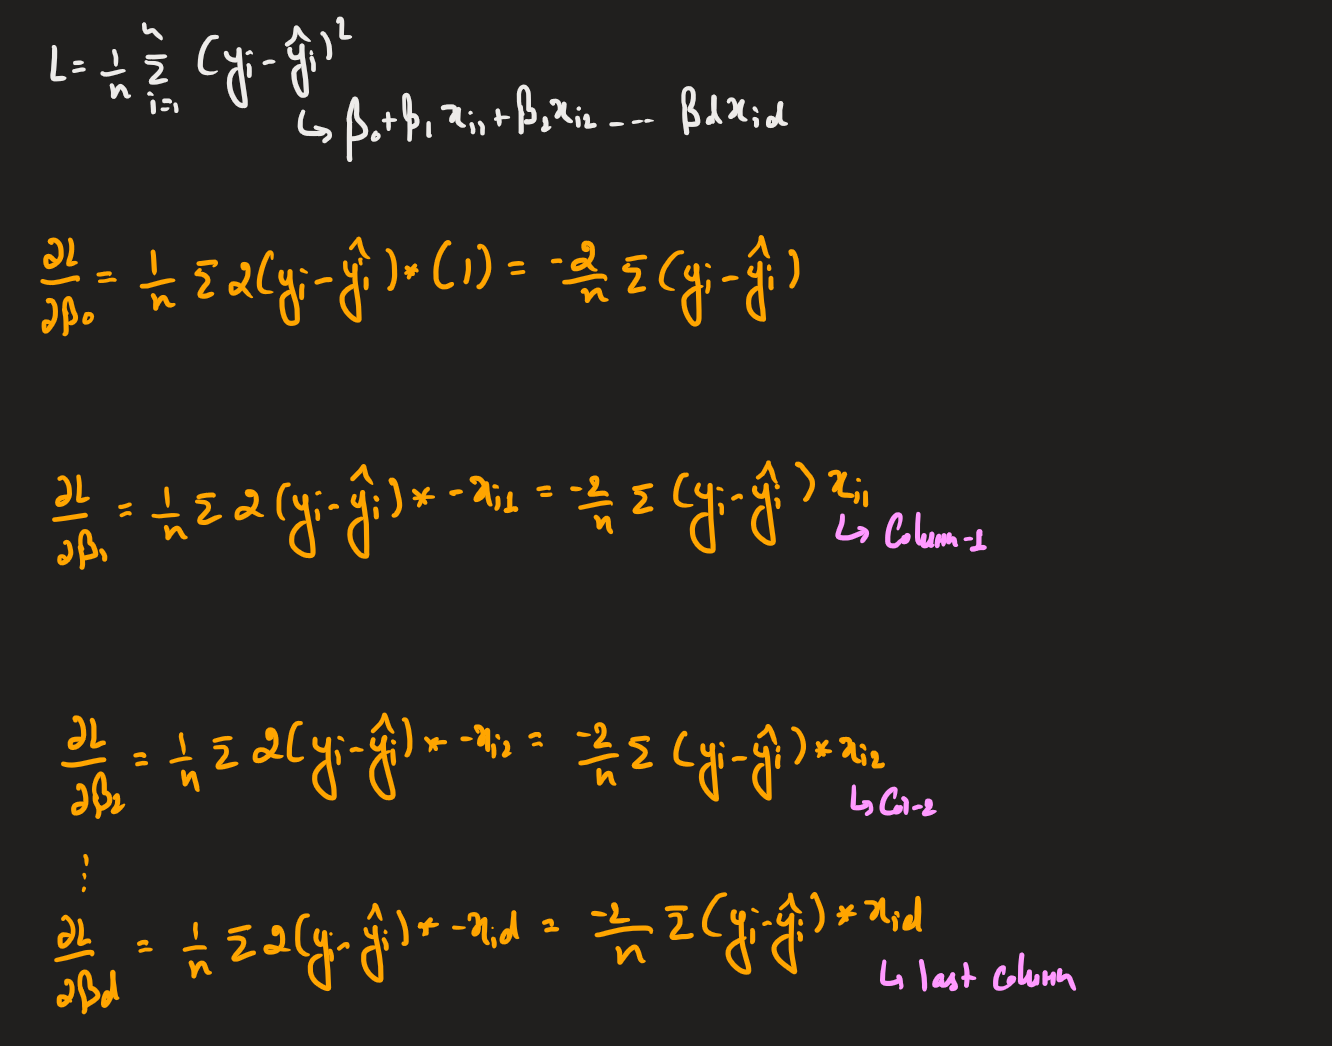

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    root_mean_squared_error,
    r2_score,
)

In [4]:
class MultipleLinearRegressionBatchGD:

    def __init__(self, learning_rate: float=0.01, epochs: int=1000, random_state: int=42):

        if learning_rate <= 0.0 :
            raise ValueError("learning_rate must be positive.")
        
        if epochs <= 0 :
            raise ValueError("epochs must be at least 1.")
        
        self.learning_rate = learning_rate
        self.epochs = epochs
        self.random_state = random_state

        self.coef_ = None
        self.intercept_ = None

        self.loss_history = []
        self.is_fittend = False
    

    def fit(self, X: np.ndarray, y: np.ndarray):

        if X.ndim != 2:
            raise ValueError("X must be a 2D array.")

        if y.ndim != 1:
            raise ValueError("y must be a 1D array.")

        if X.shape[0] != y.shape[0]:
            raise ValueError("X and y must have the same number of samples.")

        n_smaples, n_features = X.shape
        
        # Initialize coefficients and intercept randomly
        rng = np.random.default_rng(self.random_state)
        self.coef_ = rng.normal(loc=0, scale=1, size=n_features)
        self.intercept_ = rng.normal(loc=0, scale=1, size=(1,))

        self.loss_history = []

        # Batch Gradient Descent:
        # Every update uses all training samples.
        for _ in range(self.epochs):

            y_hat = X @ self.coef_ + self.intercept_

            errors = y_hat - y
            loss = np.mean(errors**2)
            self.loss_history.append(loss)

            grad_coef = (2/n_smaples) * (X.T @ errors)
            grad_intercept = (2/n_smaples) * np.sum(y_hat-y)

            self.coef_ = self.coef_ - self.learning_rate * grad_coef
            self.intercept_ = self.intercept_ - self.learning_rate * grad_intercept
        
        self.is_fittend = True
    
    def predict(self, X: np.ndarray):

        if not self.is_fittend:
            raise ValueError("Fit the model before making predictions.")

        if X.ndim != 2:
            raise ValueError("X must be a 2D array.")
        
        return X @ self.coef_ + self.intercept_


In [5]:
# Load the diabetes dataset

diabetes = load_diabetes()

X = diabetes.data
y = diabetes.target
feature_names = diabetes.feature_names

In [6]:
# Split the dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42)

In [8]:
len(X_train), len(X_test)

(353, 89)

In [11]:
# Scale the features

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

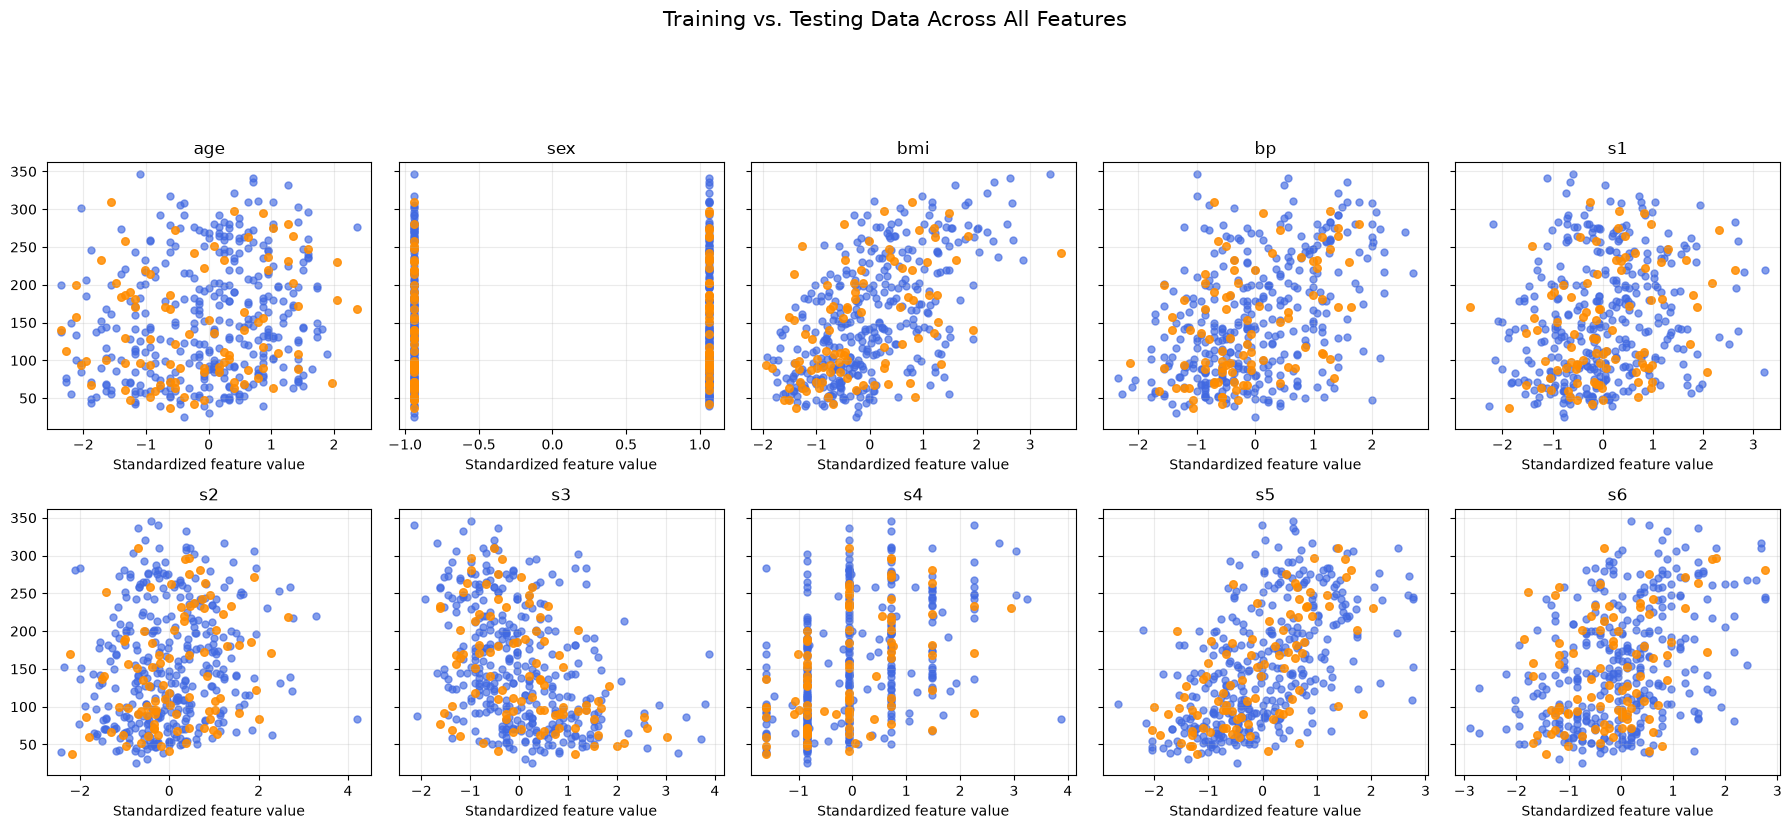

In [13]:
# Visualize the training and testing data

fig, axes = plt.subplots(
    nrows=2,
    ncols=5,
    figsize=(18, 8),
    sharey=True,
)

for i, ax in enumerate(axes.flat):

    ax.scatter(X_train_scaled[:, i],y_train,color="royalblue",alpha=0.65,s=25,label="Training Data")

    ax.scatter(X_test_scaled[:, i],y_test,color="darkorange",alpha=0.85,s=30,label="Testing Data")

    ax.set_title(feature_names[i])
    ax.set_xlabel("Standardized feature value")
    ax.grid(alpha=0.25)

fig.suptitle("Training vs. Testing Data Across All Features",fontsize=15,y=1.03)

plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()

In [76]:
# Train the model

mlr_bgd = MultipleLinearRegressionBatchGD(
    learning_rate=0.01,
    epochs=1000,
    random_state=42
)

In [77]:
mlr_bgd.fit(X_train_scaled, y_train)

In [78]:
mlr_bgd.coef_

array([  1.9369754 , -11.43617639,  26.26153493,  16.61271242,
       -10.27900097,  -2.03020643,  -7.46341288,   8.33221085,
        22.08172918,   2.59947677])

In [79]:
mlr_bgd.intercept_

array([153.73654365])

In [80]:
for name, coef in zip(feature_names, mlr_bgd.coef_):
    print(f"{name:>5}: {coef:10.4f}")

  age:     1.9370
  sex:   -11.4362
  bmi:    26.2615
   bp:    16.6127
   s1:   -10.2790
   s2:    -2.0302
   s3:    -7.4634
   s4:     8.3322
   s5:    22.0817
   s6:     2.5995


In [81]:
# Make predictions on the test data

y_pred = mlr_bgd.predict(X_test_scaled)

In [82]:
y_pred[:5]

array([140.37582051, 181.43894405, 139.71643819, 294.5514291 ,
       121.27300155])

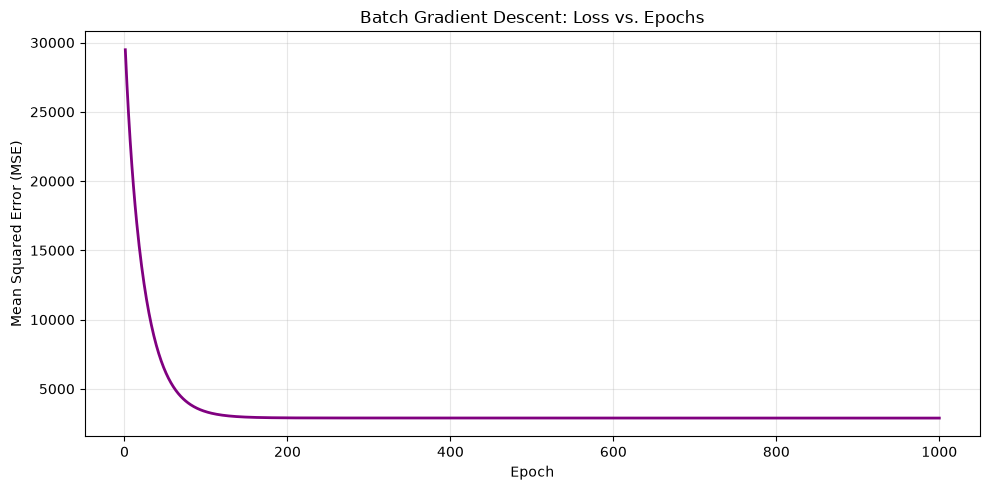

In [83]:
# Visualize the loss during training

plt.figure(figsize=(10, 5))

plt.plot(
    range(1, mlr_bgd.epochs + 1),
    mlr_bgd.loss_history,
    color="purple",
    linewidth=2,
)

plt.title("Batch Gradient Descent: Loss vs. Epochs")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error (MSE)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [84]:
# Evaluate the model

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = root_mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"MAE:  {mae:.4f}")
print(f"MSE:  {mse:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R²:   {r2:.4f}")

MAE:  42.8805
MSE:  2885.9604
RMSE: 53.7211
R²:   0.4553


***
***
***

In [85]:
from sklearn.linear_model import LinearRegression

In [86]:
lr = LinearRegression()

lr.fit(X_train_scaled, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](10,)","[ 1.75,-11.51, 25.61,..., 13.14, 35.16, 2.35]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,153.7
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,10
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(10)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](10,)","[37.43,22.84,21.02,...,12.37, 5.17, 1.81]"


In [87]:
lr.coef_

array([  1.75375799, -11.51180908,  25.60712144,  16.82887167,
       -44.44885564,  24.64095356,   7.67697768,  13.1387839 ,
        35.16119521,   2.35136365])

In [91]:
mlr_bgd.coef_

array([  1.9369754 , -11.43617639,  26.26153493,  16.61271242,
       -10.27900097,  -2.03020643,  -7.46341288,   8.33221085,
        22.08172918,   2.59947677])

In [88]:
lr.intercept_

np.float64(153.73654390934846)

In [92]:
mlr_bgd.intercept_

array([153.73654365])

In [89]:
y_pred = lr.predict(X_test_scaled)

In [90]:
# Evaluate the model

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = root_mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"MAE:  {mae:.4f}")
print(f"MSE:  {mse:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R²:   {r2:.4f}")

MAE:  42.7941
MSE:  2900.1936
RMSE: 53.8534
R²:   0.4526
